<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta4_g%C3%B6rev3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: NVIDIA RTX PRO 6000 Blackwell Server Edition


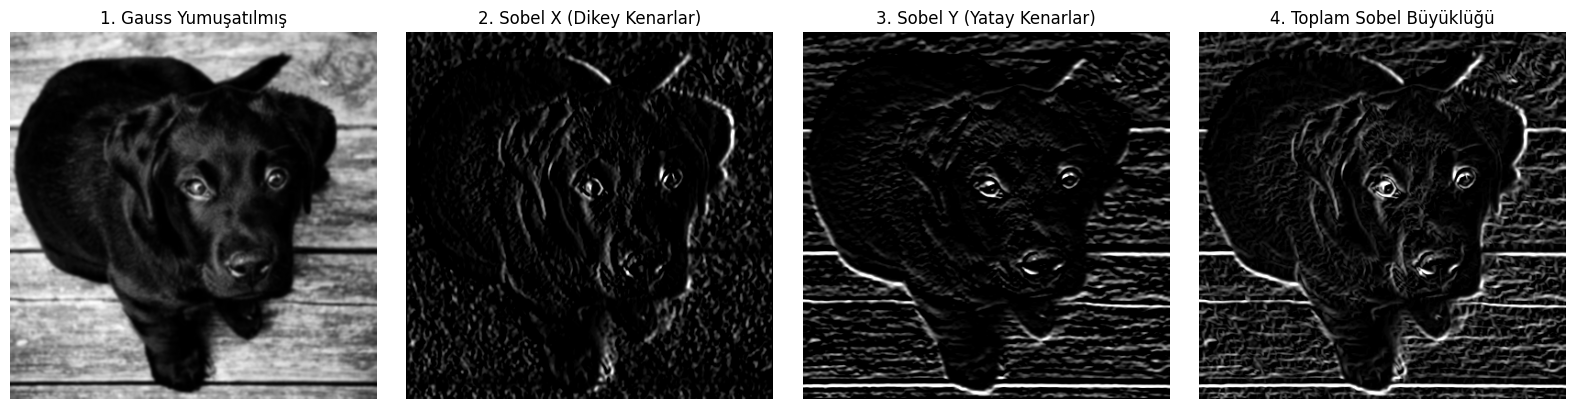

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# 1. Test için örnek bir görüntü indirelim
url = 'https://picsum.photos/id/237/400/400'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img = cv2.imdecode(arr, cv2.IMREAD_GRAYSCALE)

# (İsteğe bağlı) Kendi bilgisayarından resim yüklemek istersen aşağıdaki satırları açabilirsin:
# from google.colab import files
# uploaded = files.upload()
# filename = list(uploaded.keys())[0]
# img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

# 2. Gauss Filtresi ile Görüntüyü Hafif Yumuşatma
blurred_img = cv2.GaussianBlur(img, (5, 5), 0)

# 3. 3x3 Sobel Kernelleri
# Yatay Türev (Dikey Kenarları Bulur)
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

# Dikey Türev (Yatay Kenarları Bulur)
sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float32)

# 4. Filtreleri Görüntü Üzerinde Uygulama
filtered_sobel_x = cv2.filter2D(blurred_img, -1, sobel_x)
filtered_sobel_y = cv2.filter2D(blurred_img, -1, sobel_y)

# İsteğe Bağlı: Toplam Kenar Büyüklüğü (Gradient Magnitude)
sobel_magnitude = cv2.magnitude(filtered_sobel_x.astype(np.float32), filtered_sobel_y.astype(np.float32))
sobel_magnitude = cv2.convertScaleAbs(sobel_magnitude)

# 5. Sonuçları Görselleştirme
plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(blurred_img, cmap='gray')
plt.title('1. Gauss Yumuşatılmış')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(filtered_sobel_x, cmap='gray')
plt.title('2. Sobel X (Dikey Kenarlar)')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(filtered_sobel_y, cmap='gray')
plt.title('3. Sobel Y (Yatay Kenarlar)')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(sobel_magnitude, cmap='gray')
plt.title('4. Toplam Sobel Büyüklüğü')
plt.axis('off')

plt.tight_layout()
plt.show()